# Validate Track Thumbnails

Visual validation of the `TrackThumbnailDataset` before committing to bulk generation.

**Steps covered:**
1. Load one study and build the dataset
2. Inspect dataset stats (size, label balance, metadata)
3. Visualise random normal / anomalous thumbnails side-by-side
4. Spot-check: overlay thumbnail on map to verify spatial correctness
5. Edge-case checks (stationary, very short chunks)
6. Try different `chunk_size` and `img_size` parameters

In [2]:
import sys
sys.path.insert(0, '..')  # repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from movebench.study import Study
from movebench.datasets.thumbnails import (
    render_track,
    chunk_individual,
    aggregate_labels,
    TrackThumbnailDataset,
)
from movebench.trajectories import load_trajectories_csv, LON_COL, LAT_COL, INDIVIDUAL_COL, TIME_COL

## 1. Load a study

In [3]:
# ---- change this to any study you want to validate ----
STUDY_ID = "atlas_bats"
# -------------------------------------------------------

study = Study(STUDY_ID)
print("Study dir:", study.study_dir)

# Quick peek at raw trajectories
raw = load_trajectories_csv(study.trajectories_path)
print(f"Total fixes: {len(raw):,}")
print(f"Individuals: {raw[INDIVIDUAL_COL].nunique()}")
outlier_cols = [c for c in raw.columns if 'outlier' in c.lower()]
print(f"Outlier columns: {outlier_cols}")
if outlier_cols:
    print(raw[outlier_cols].apply(lambda c: c.fillna(False).astype(bool).sum()))

Study dir: /archive/vision/beery/movebench/point_based_downloads/studies_10ind/atlas_bats
Total fixes: 40,112
Individuals: 3
Outlier columns: ['manually-marked-outlier', 'system-outlier', 'speed-outlier']
manually-marked-outlier    9100
system-outlier             8769
speed-outlier               331
dtype: int64


## 2. Build dataset and inspect stats

In [33]:
ds = study.thumbnail_dataset(
    split=None,        # load all splits for validation
    img_size=64,
    chunk_size=25,
    min_chunk_size=1,
    marker_radius=2,
)

X = ds.numpy()          # (N, 64, 64) uint8
meta = ds.metadata()

print(f"Dataset size: {len(ds):,} chunks")
print(f"Image array shape: {X.shape}")
print(f"Label columns: {ds.label_columns()}")
print()
print("Label proportions (mean fraction of flagged fixes per chunk):")
for col in ds.label_columns():
    y = ds.labels(col)
    nonzero = (y > 0).sum()
    print(f"  {col}: mean={y.mean():.4f}  chunks_with_any={nonzero} ({nonzero/len(y)*100:.1f}%)")

Dataset size: 1,605 chunks
Image array shape: (1605, 64, 64)
Label columns: ['outlier_frac', 'frac_manually_marked_outlier', 'frac_system_outlier', 'frac_speed_outlier']

Label proportions (mean fraction of flagged fixes per chunk):
  outlier_frac: mean=0.2271  chunks_with_any=635 (39.6%)
  frac_manually_marked_outlier: mean=0.2271  chunks_with_any=635 (39.6%)
  frac_system_outlier: mean=0.2189  chunks_with_any=593 (36.9%)
  frac_speed_outlier: mean=0.0082  chunks_with_any=96 (6.0%)


In [34]:
# Metadata overview
meta.head()

,individual_id,chunk_idx,split,start_time,end_time,n_fixes,center_lat,center_lon,lat_min,lat_max,lon_min,lon_max,n_manually_marked_outlier,frac_manually_marked_outlier,n_system_outlier,frac_system_outlier,n_speed_outlier,frac_speed_outlier,n_outlier_fixes,outlier_frac
0,972001004424,0,None,2018-05-05 10:00:06,2018-05-05 10:03:18,25,33.075171,35.572272,33.074549,33.075551,35.571213,35.572619,24,0.96,23,0.92,1,0.04,24,0.96
1,972001004424,1,None,2018-05-05 10:03:26,2018-05-05 10:51:30,25,33.075056,35.572148,33.069680,33.076511,35.561907,35.574458,25,1.00,25,1.00,0,0.00,25,1.00
2,972001004424,2,None,2018-05-05 10:51:38,2018-05-05 10:58:02,25,33.075478,35.573130,33.074502,33.076695,35.571433,35.574713,25,1.00,25,1.00,0,0.00,25,1.00
3,972001004424,3,None,2018-05-05 11:14:26,2018-05-05 11:18:42,25,33.075378,35.572568,33.074986,33.077198,35.572301,35.572785,23,0.92,23,0.92,0,0.00,23,0.92
4,972001004424,4,None,2018-05-05 11:18:50,2018-05-05 11:23:14,25,33.075344,35.572660,33.075021,33.075772,35.572226,35.573339,25,1.00,25,1.00,0,0.00,25,1.00


In [35]:
ds.labels()

array([0.96, 1.  , 1.  , ..., 1.  , 1.  , 1.  ],
      shape=(1605,), dtype=float32)

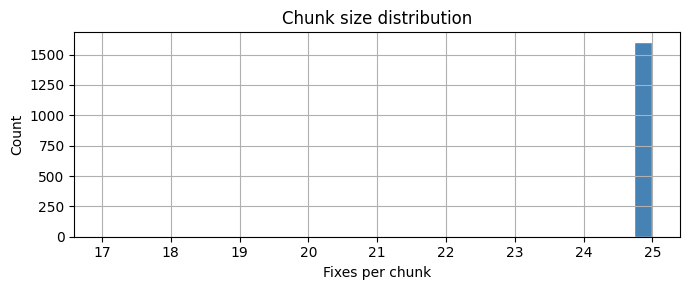

In [36]:
# Fix count distribution across chunks
fig, ax = plt.subplots(figsize=(7, 3))
meta['n_fixes'].hist(bins=30, ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Fixes per chunk')
ax.set_ylabel('Count')
ax.set_title('Chunk size distribution')
plt.tight_layout()
plt.show()

## 3. Visual inspection — random sample of normal vs anomalous

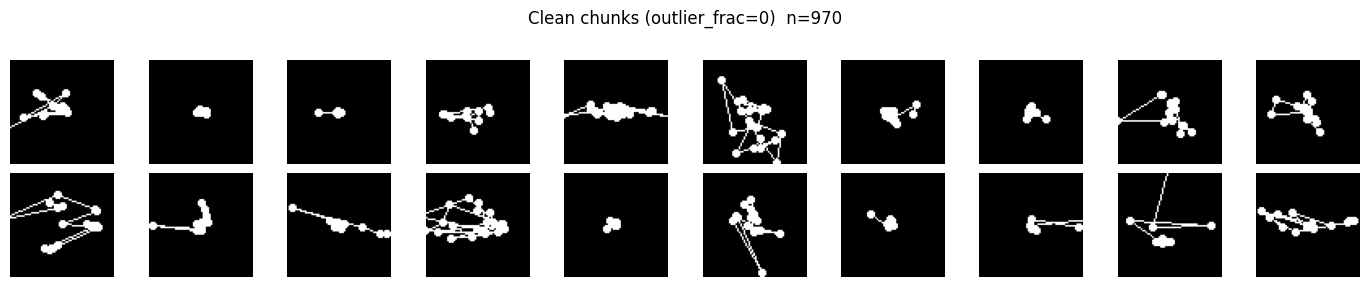

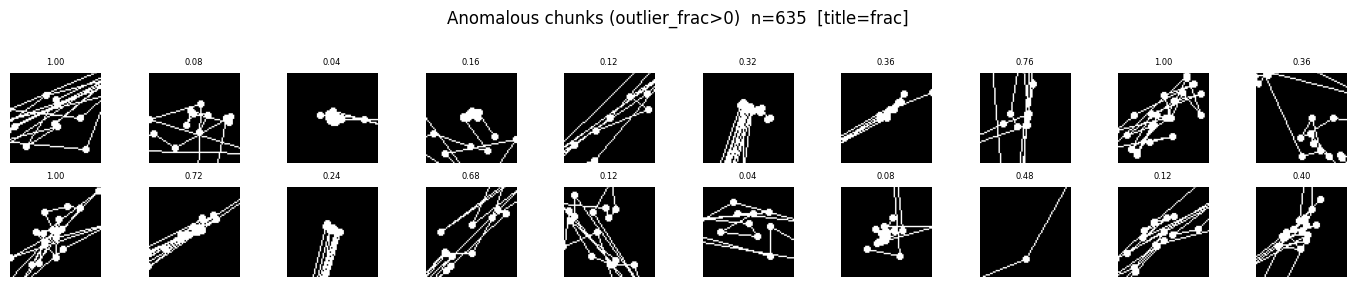

In [40]:
def show_thumbnails(images, titles=None, ncols=10, cmap='gray', title=None):
    n = len(images)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.4, nrows * 1.4))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(images[i], cmap=cmap, vmin=0, vmax=255)
            if titles is not None:
                ax.set_title(titles[i], fontsize=6)
        ax.axis('off')
    if title:
        fig.suptitle(title, fontsize=12, y=1.01)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(42)
# Use outlier_frac > 0 as the positive condition
y = ds.labels('outlier_frac')

neg_idx = np.where(y == 0)[0]
pos_idx = np.where(y > 0)[0]

n_show = 20
sample_neg = rng.choice(neg_idx, size=min(n_show, len(neg_idx)), replace=False)
sample_pos = rng.choice(pos_idx, size=min(n_show, len(pos_idx)), replace=False)

# Show titles with the actual outlier fraction for positive chunks
pos_titles = [f"{y[i]:.2f}" for i in sample_pos]

show_thumbnails(X[sample_neg], title=f'Clean chunks (outlier_frac=0)  n={len(neg_idx)}')
if len(pos_idx) > 0:
    show_thumbnails(X[sample_pos], titles=pos_titles,
                    title=f'Anomalous chunks (outlier_frac>0)  n={len(pos_idx)}  [title=frac]')
else:
    print("No anomalous chunks found — check outlier columns above.")

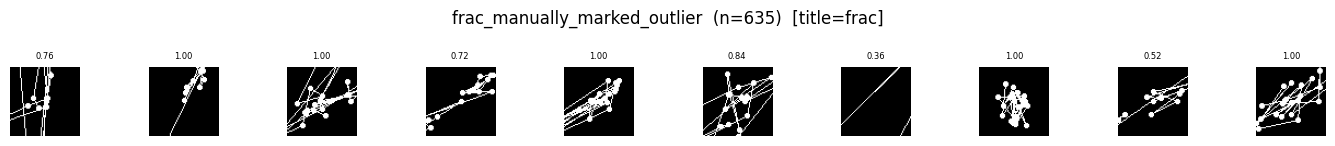

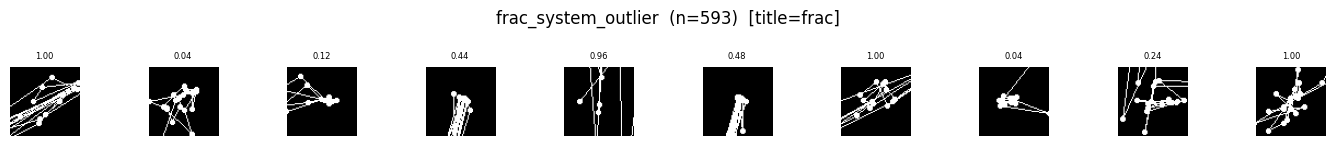

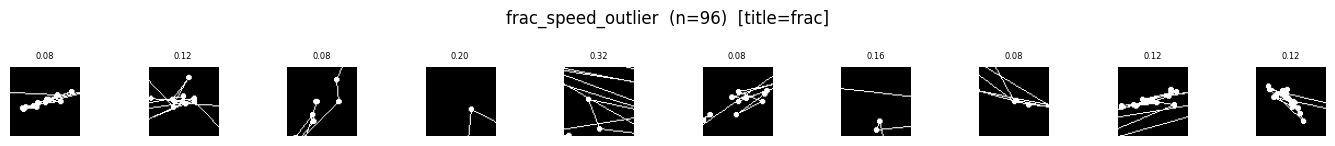

In [38]:
# Per-type grids: show chunks that have any fraction > 0 for each outlier type
for col in ds.label_columns():
    if col == 'outlier_frac':
        continue
    y_col = ds.labels(col)
    pos = np.where(y_col > 0)[0]
    if len(pos) == 0:
        print(f"{col}: no positives")
        continue
    sample = rng.choice(pos, size=min(10, len(pos)), replace=False)
    titles = [f"{y_col[i]:.2f}" for i in sample]
    show_thumbnails(X[sample], titles=titles, title=f'{col}  (n={len(pos)})  [title=frac]', ncols=10)

## 4. Spatial spot-check — overlay chunk bounding boxes on a map

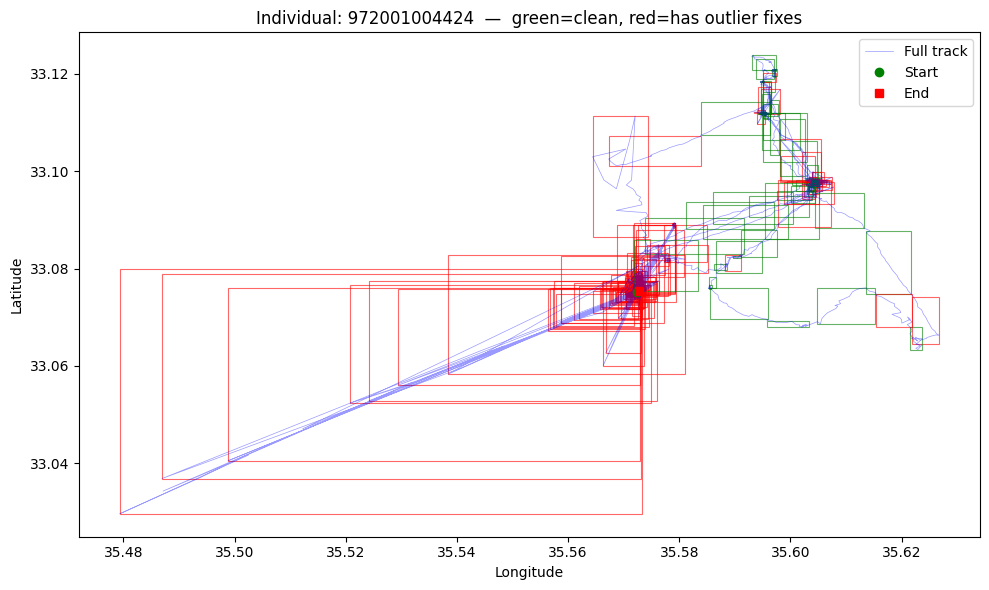

In [39]:
# Pick one individual and show their full track + chunk bounding boxes
individual = meta['individual_id'].iloc[0]
ind_meta = meta[meta['individual_id'] == individual].reset_index(drop=True)
ind_raw = raw[raw[INDIVIDUAL_COL] == individual].sort_values(TIME_COL)

fig, ax = plt.subplots(figsize=(10, 6))

# Full track
ax.plot(ind_raw[LON_COL], ind_raw[LAT_COL], 'b-', lw=0.5, alpha=0.4, label='Full track')
ax.plot(ind_raw[LON_COL].iloc[0], ind_raw[LAT_COL].iloc[0], 'go', ms=6, label='Start')
ax.plot(ind_raw[LON_COL].iloc[-1], ind_raw[LAT_COL].iloc[-1], 'rs', ms=6, label='End')

# Chunk bounding boxes coloured by outlier_frac (green=0, red=positive)
for _, row in ind_meta.iterrows():
    color = 'red' if row.get('outlier_frac', 0.0) > 0 else 'green'
    w = row['lon_max'] - row['lon_min']
    h = row['lat_max'] - row['lat_min']
    rect = mpatches.Rectangle(
        (row['lon_min'], row['lat_min']), w, h,
        linewidth=0.8, edgecolor=color, facecolor='none', alpha=0.6
    )
    ax.add_patch(rect)

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'Individual: {individual}  —  green=clean, red=has outlier fixes')
ax.legend()
plt.tight_layout()
plt.show()

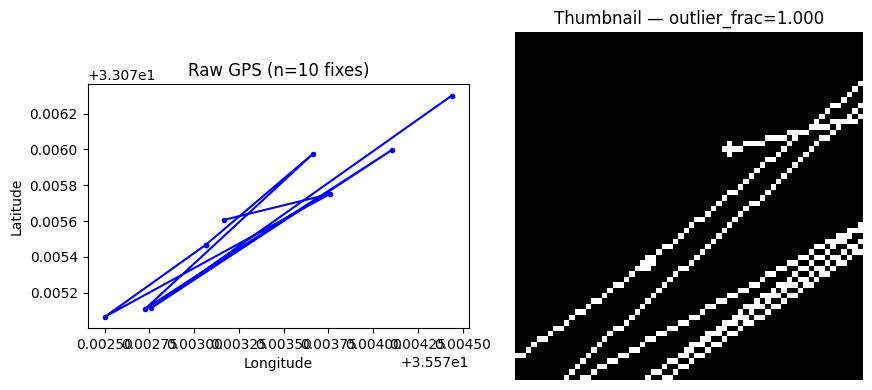

In [23]:
# Pick a specific chunk from this individual and compare thumbnail to raw track
chunk_id = 6
chunk_row = ind_meta.iloc[chunk_id]
chunk_idx_global = meta[(meta['individual_id'] == individual) & (meta['chunk_idx'] == chunk_id)].index[0]

# Reconstruct the fixes in this chunk from raw data
start_t = chunk_row['start_time']
end_t = chunk_row['end_time']
chunk_fixes = ind_raw[(ind_raw[TIME_COL] >= start_t) & (ind_raw[TIME_COL] <= end_t)]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

# Left: raw GPS line
axes[0].plot(chunk_fixes[LON_COL], chunk_fixes[LAT_COL], 'b-o', ms=3)
axes[0].set_title(f'Raw GPS (n={len(chunk_fixes)} fixes)')
axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude')
axes[0].set_aspect('equal')

# Right: rendered thumbnail
axes[1].imshow(X[chunk_idx_global], cmap='gray', vmin=0, vmax=255)
frac = meta.loc[chunk_idx_global, 'outlier_frac']
label_str = f'outlier_frac={frac:.3f}' if frac > 0 else 'clean'
axes[1].set_title(f'Thumbnail — {label_str}')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 5. Edge-case checks

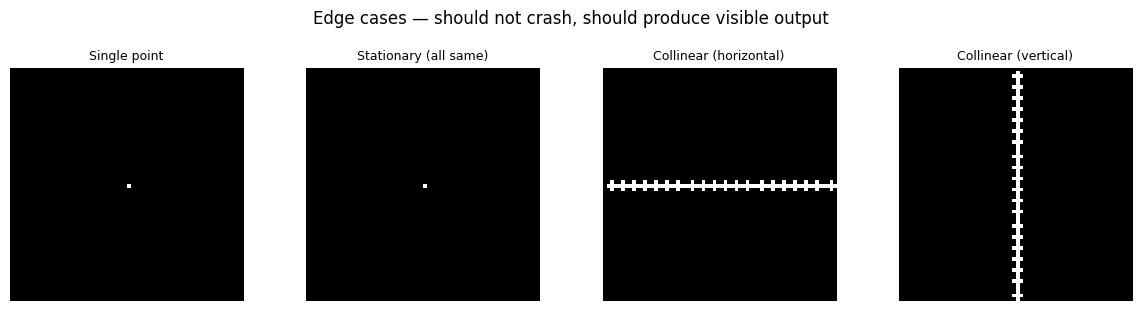

In [24]:
# Synthetic edge cases for render_track
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

cases = [
    ('Single point', np.array([0.0]), np.array([0.0])),
    ('Stationary (all same)', np.full(10, 10.5), np.full(10, 45.3)),
    ('Collinear (horizontal)', np.linspace(0, 1, 20), np.zeros(20)),
    ('Collinear (vertical)', np.zeros(20), np.linspace(0, 1, 20)),
]

for ax, (title, lons, lats) in zip(axes, cases):
    img = render_track(lons, lats, img_size=64)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=9)
    ax.axis('off')

plt.suptitle('Edge cases — should not crash, should produce visible output', y=1.02)
plt.tight_layout()
plt.show()

In [26]:
# Verify a study with no outlier columns produces outlier_frac=0 everywhere
ds_no_labels = TrackThumbnailDataset(
    trajectories_path=study.trajectories_path,
    split=None,
    chunk_size=10,
    min_chunk_size=1,
)
print("label_columns():", ds_no_labels.label_columns())
print("outlier_frac max:", ds_no_labels.labels('outlier_frac').max())

label_columns(): ['outlier_frac', 'frac_manually_marked_outlier', 'frac_system_outlier', 'frac_speed_outlier']
outlier_frac max: 1.0


## 6. Parameter sensitivity — chunk_size and img_size

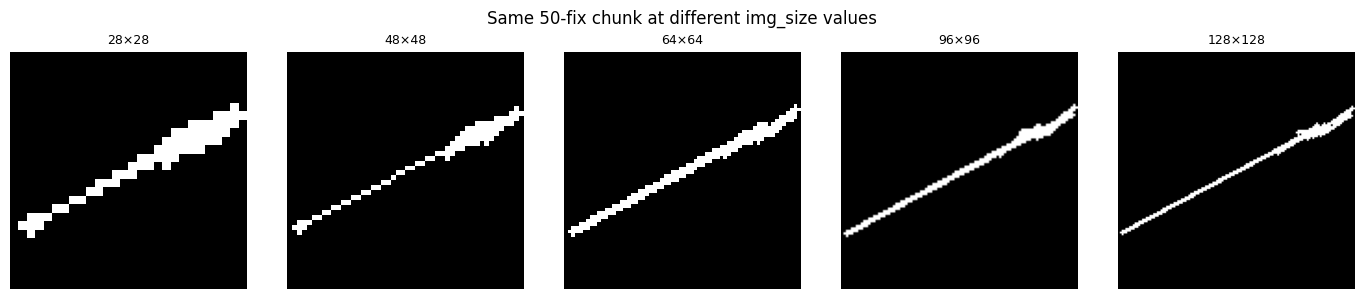

In [27]:
# Same individual, same chunk position, rendered at different img_sizes
ind_raw_sample = ind_raw.head(50)  # first 50 fixes
lons = ind_raw_sample[LON_COL].to_numpy()
lats = ind_raw_sample[LAT_COL].to_numpy()

sizes = [28, 48, 64, 96, 128]
fig, axes = plt.subplots(1, len(sizes), figsize=(14, 3))
for ax, sz in zip(axes, sizes):
    img = render_track(lons, lats, img_size=sz, line_width=1 if sz < 64 else 2)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{sz}×{sz}', fontsize=9)
    ax.axis('off')
plt.suptitle('Same 50-fix chunk at different img_size values')
plt.tight_layout()
plt.show()

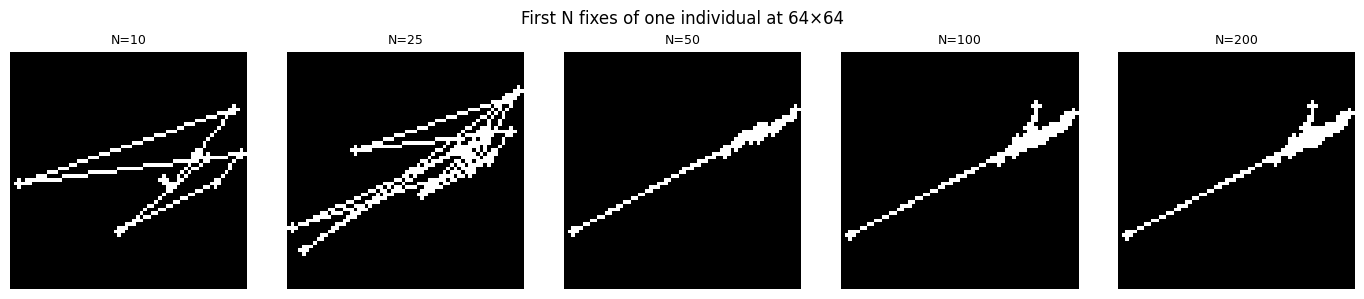

In [28]:
# Same location, different chunk_sizes — does density look reasonable?
chunk_sizes = [10, 25, 50, 100, 200]
fig, axes = plt.subplots(1, len(chunk_sizes), figsize=(14, 3))
for ax, n in zip(axes, chunk_sizes):
    fixes = ind_raw.head(n)
    if len(fixes) < 2:
        ax.axis('off'); continue
    img = render_track(fixes[LON_COL].to_numpy(), fixes[LAT_COL].to_numpy(), img_size=64)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'N={n}', fontsize=9)
    ax.axis('off')
plt.suptitle('First N fixes of one individual at 64×64')
plt.tight_layout()
plt.show()

## 7. PyTorch DataLoader smoke test

In [29]:
from torch.utils.data import DataLoader

loader = DataLoader(ds, batch_size=32, shuffle=True)
batch_tensors, batch_labels = next(iter(loader))

print('Tensor batch shape:', batch_tensors.shape)    # (32, 1, 64, 64)
print('Tensor dtype:', batch_tensors.dtype)           # float32
print('Tensor range:', batch_tensors.min().item(), '–', batch_tensors.max().item())  # [0, 1]
print('Label keys:', list(batch_labels.keys()))
print('outlier_frac batch:', batch_labels['outlier_frac'])  # float32 in [0, 1]

Tensor batch shape: torch.Size([32, 1, 64, 64])
Tensor dtype: torch.float32
Tensor range: 0.0 – 1.0
Label keys: ['outlier_frac', 'frac_manually_marked_outlier', 'frac_system_outlier', 'frac_speed_outlier']
outlier_frac batch: tensor([1.0000, 0.0000, 0.9000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 1.0000,
        0.0000, 0.0000, 0.0000, 0.2000, 0.0000, 0.0000, 0.1000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.5000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 1.0000], dtype=torch.float64)


## 8. Fixed per-individual scale + fix markers

Uses `scale_mode='individual'` (default): each chunk is rendered at the
individual's median chunk extent, so anomalously large bounding boxes visibly
overflow the image.  Fix markers make isolated outlier points easy to spot.

Dataset size: 4,013

Per-individual median chunk extent:
  972001004424: 0.0011° ≈ 0.1 km
  972001004449: 0.0010° ≈ 0.1 km
  972001004452: 0.0010° ≈ 0.1 km


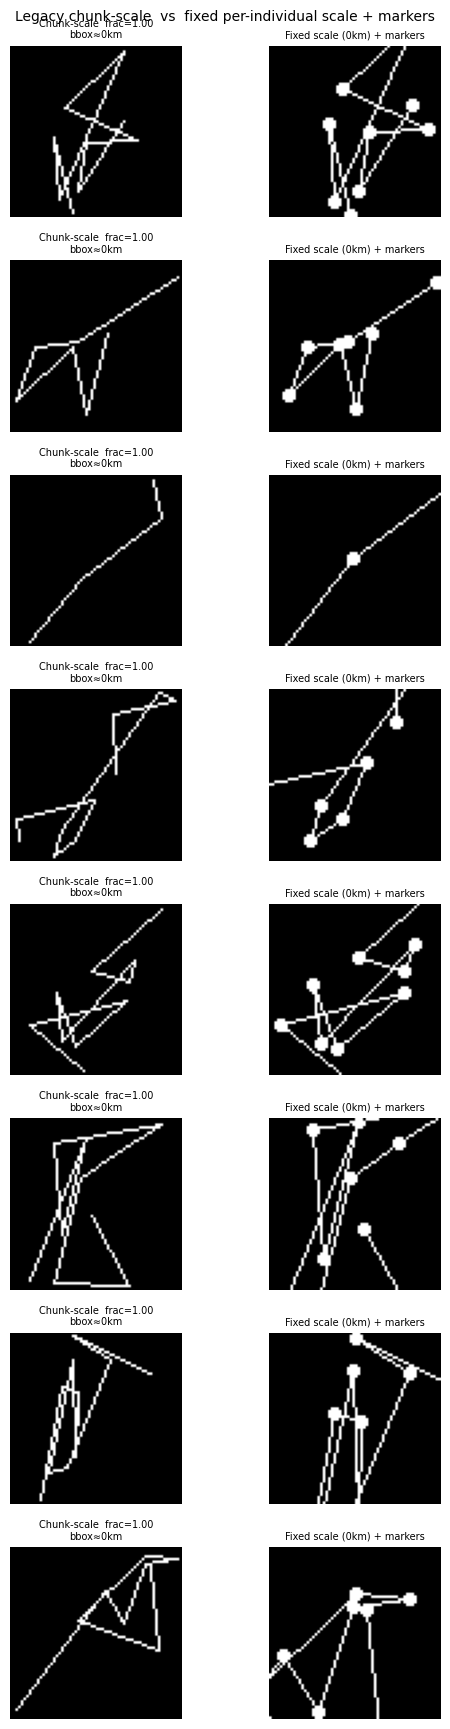

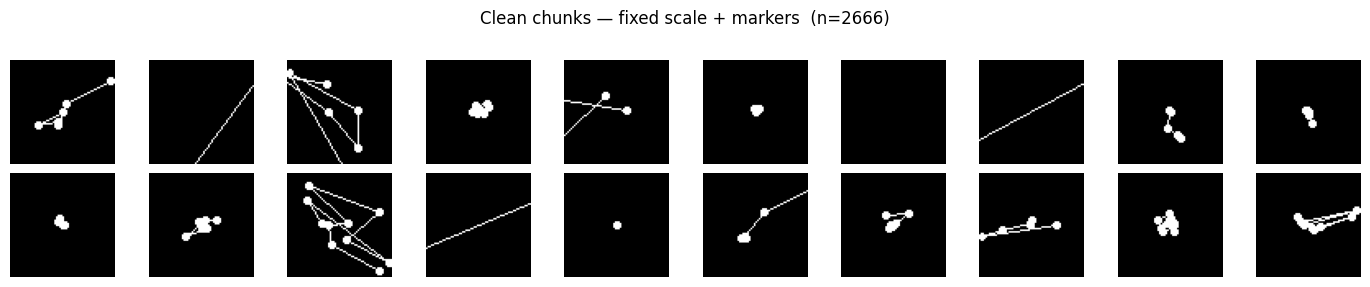

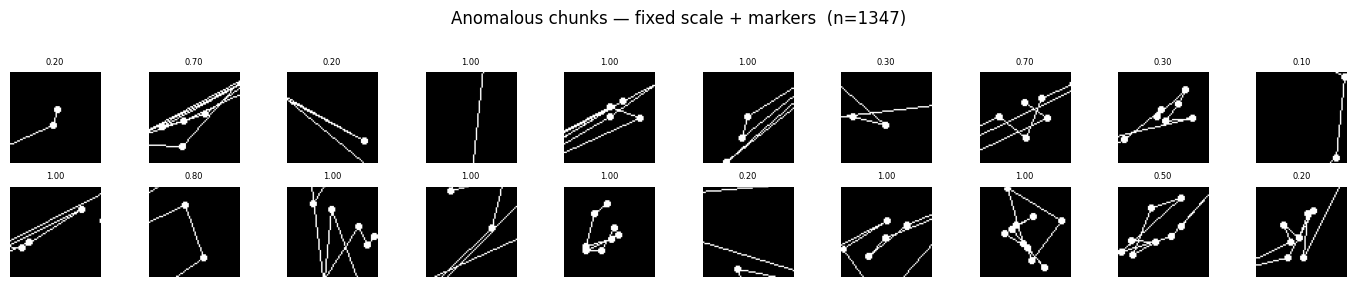

In [30]:
from movebench.datasets.thumbnails import render_track, compute_individual_scales

# Reload dataset with new defaults: individual scale + markers
ds_v2 = study.thumbnail_dataset(
    split=None,
    img_size=64,
    chunk_size=10,
    min_chunk_size=1,
    scale_mode='individual',
    marker_radius=2,
)
X_v2 = ds_v2.numpy()
meta_v2 = ds_v2.metadata()
print(f'Dataset size: {len(ds_v2):,}')

# Per-individual scales
ind_scales = compute_individual_scales(raw, chunk_size=50, min_chunk_size=10)
print('\nPer-individual median chunk extent:')
for ind, deg in ind_scales.items():
    print(f'  {ind}: {deg:.4f}\u00b0 \u2248 {deg*111:.1f} km')

# Side-by-side: top anomalous chunks, old vs new
y_v2 = ds_v2.labels('outlier_frac')
top = np.argsort(y_v2)[::-1][:8]

n = len(top)
fig, axes = plt.subplots(n, 2, figsize=(6, n * 2.2))

for row, idx in enumerate(top):
    rm = meta_v2.iloc[idx]
    ind_id, start_t, end_t = rm['individual_id'], rm['start_time'], rm['end_time']
    ind_raw_ = raw[raw[INDIVIDUAL_COL] == ind_id].sort_values(TIME_COL)
    cf = ind_raw_[(ind_raw_[TIME_COL] >= start_t) & (ind_raw_[TIME_COL] <= end_t)]
    lons_, lats_ = cf[LON_COL].to_numpy(), cf[LAT_COL].to_numpy()

    bbox_km = max(
        (rm['lon_max'] - rm['lon_min']) * 111,
        (rm['lat_max'] - rm['lat_min']) * 111,
    )
    fscale_km = ind_scales.get(ind_id, 0) * 111
    frac = rm['outlier_frac']

    # Legacy chunk-scale render for comparison
    img_old = render_track(lons_, lats_, img_size=64, marker_radius=0, fixed_range=None)
    # New fixed-scale + markers
    img_new = X_v2[idx]

    axes[row, 0].imshow(img_old, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f'Chunk-scale  frac={frac:.2f}\nbbox\u2248{bbox_km:.0f}km', fontsize=7)
    axes[row, 0].axis('off')
    axes[row, 1].imshow(img_new, cmap='gray', vmin=0, vmax=255)
    axes[row, 1].set_title(f'Fixed scale ({fscale_km:.0f}km) + markers', fontsize=7)
    axes[row, 1].axis('off')

plt.suptitle('Legacy chunk-scale  vs  fixed per-individual scale + markers', fontsize=10)
plt.tight_layout()
plt.show()

# Also show a grid of clean vs anomalous with the new rendering
y_v2_arr = ds_v2.labels('outlier_frac')
neg_idx = np.where(y_v2_arr == 0)[0]
pos_idx = np.where(y_v2_arr > 0)[0]
sample_neg = rng.choice(neg_idx, size=min(20, len(neg_idx)), replace=False)
sample_pos = rng.choice(pos_idx, size=min(20, len(pos_idx)), replace=False)
pos_titles = [f"{y_v2_arr[i]:.2f}" for i in sample_pos]

show_thumbnails(X_v2[sample_neg], title=f'Clean chunks — fixed scale + markers  (n={len(neg_idx)})')
show_thumbnails(X_v2[sample_pos], titles=pos_titles,
                title=f'Anomalous chunks — fixed scale + markers  (n={len(pos_idx)})')
